# Bakery Sales, Waste and Profitability Analysis
### Identifying What Drives Loss-Making Sales in a Multi-Store Bakery

**Author:** Sneha Yadav  |  **Programme:** IBM Internship Project  

---

## 1. Introduction
Bakeries sell fresh products that spoil quickly. Even when sales look healthy, money can be lost through
**discounts** and **unsold stock that has to be thrown away (waste)**. This project analyses a bakery
transaction dataset to understand *where* profit is made, *where* it is lost, and *why*.

The notebook follows a simple path: load the data, check its quality, explore it with charts, test a few
ideas with basic statistics, and finally build a small machine-learning model that flags
**loss-making transactions** using only information that is available *before* the waste is known.

## 2. Problem Statement
Although the bakery records about 3.44 million currency units in sales across three stores over two years, the profit column in the dataset
adds up to a **net loss**. The management needs to know which products, categories, promotions and
shelf-life groups are responsible, so that production and discount decisions can be improved.

## 3. Project Objectives
1. Inspect the dataset and check its quality (missing values, duplicates, inconsistent values).
2. Clean the data and create useful new features (for example, month, hour, profit margin, loss flag).
3. Measure revenue, waste cost and profit by product, category, store, season and time.
4. Study how **discounts and promotions** relate to profit.
5. Study how **shelf life and unsold stock** relate to waste and profit.
6. Build and honestly evaluate a classification model that predicts whether a transaction will be loss-making.
7. Give clear, data-backed recommendations.

## 4. Dataset Description and Source
* **File:** `bakery_synthetic_dataset_csv__1_.xlsx` (sheet: `bakery_synthetic_dataset`)
* **Source:** The dataset was provided privately for this internship assignment. No public link is available.
  It is described in its file name as a *synthetic* dataset, so the findings describe **this dataset**
  and should not be assumed to hold for a real bakery.
* **Size:** 16,569 rows (one row = one product line in a customer transaction) and 41 columns.
* **Period:** 1 Jan 2023 – 31 Dec 2024, three stores (ST01, ST02, ST03).
* **No single target column is supplied.** Because the business problem is about profit, we use `Profit`
  to define the target `Is_Loss` (1 if profit < 0).

**Where to place the file:** put the Excel file in a folder called `data/` next to this notebook, i.e.
`data/bakery_synthetic_dataset_csv__1_.xlsx`.

## 5. Importing Libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from IPython.display import display
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["figure.dpi"] = 100
RANDOM_STATE = 42

import os
os.makedirs("figures", exist_ok=True)   # charts are also saved here for the report

## 6. Loading the Dataset
We read the Excel file with `pandas`. If you moved the file, change `DATA_PATH` below.

In [2]:
DATA_PATH = "data/bakery_synthetic_dataset_csv__1_.xlsx"
df = pd.read_excel(DATA_PATH)
print("Loaded:", DATA_PATH)
display(df.head())

Loaded: data/bakery_synthetic_dataset_csv__1_.xlsx


,Transaction_ID,Date,Time,Customer_ID,Customer_Age,Customer_Gender,Product,Category,Quantity,Unit_Price,Discount_Percentage,Discount_Amount,Selling_Price,Total_Bill,Payment_Method,Weather,Temperature,Season,Day_of_Week,Weekend,Festival,Store_ID,Employee_ID,Shelf_Life_Days,Manufacturing_Date,Expiry_Date,Stock_Available,Units_Produced,Units_Sold,Unsold_Units,Expiry_Risk,Promotion_Applied,Promotion_Type,Promotion_Score,Customer_Rating,Customer_Segment,Loyalty_Member,Profit,Waste_Cost,Recommended_Product,Recommended_Discount
0,TXN000038,2023-01-01,07:13:00,CUST01289,32,Male,Rusk,Biscuits & Cookies,1,34.79,19.2,6.68,28.11,28.11,UPI,Cold,10.2,Winter,Sunday,Yes,New Year,ST01,EMP016,60,2023-01-01,2023-03-02,3,10,7,3,Medium,Yes,Festival,100,4,Young Professional,Yes,-4.28,7.71,Rusk,13.0
1,TXN000039,2023-01-01,07:13:00,CUST01289,32,Male,Peanut Butter,Spreads,4,176.62,17.0,120.10,146.59,586.38,UPI,Cold,10.2,Winter,Sunday,Yes,New Year,ST01,EMP016,250,2023-01-01,2023-09-08,3,10,7,3,Low,Yes,Festival,100,4,Young Professional,Yes,-105.15,171.43,Bread,9.0
2,TXN000040,2023-01-01,07:13:00,CUST01289,32,Male,Black Forest Cake,Cakes,2,448.03,17.7,158.60,368.73,737.46,UPI,Cold,10.2,Winter,Sunday,Yes,New Year,ST01,EMP016,3,2023-01-01,2023-01-04,2,4,2,2,Medium,Yes,Festival,100,4,Young Professional,Yes,-461.14,520.00,Soft Drink,14.7
3,TXN000041,2023-01-01,07:13:00,CUST01289,32,Male,Honey,Spreads,4,219.12,12.9,113.07,190.85,763.41,UPI,Cold,10.2,Winter,Sunday,Yes,New Year,ST01,EMP016,365,2023-01-01,2024-01-01,3,10,7,3,Low,Yes,Festival,100,4,Young Professional,Yes,-92.52,222.86,Honey,3.3
4,TXN000043,2023-01-01,08:15:00,CUST01077,17,Female,Tea,Beverages,2,29.85,13.7,8.18,25.76,51.52,UPI,Cold,10.2,Winter,Sunday,Yes,New Year,ST02,EMP019,1,2023-01-01,2023-01-02,6,11,5,6,High,Yes,Festival,100,4,Student,No,-0.66,24.00,Biscuit,25.2


## 7. Exploratory Data Analysis (EDA)
### 7.1 Shape, columns and data types

In [3]:
print("Rows, columns:", df.shape)
print("Date range:", df["Date"].min().date(), "to", df["Date"].max().date())
info = pd.DataFrame({"dtype": df.dtypes.astype(str), "non_null": df.notna().sum(), "unique_values": df.nunique()})
display(info)

Rows, columns: (16569, 41)
Date range: 2023-01-01 to 2024-12-31


,dtype,non_null,unique_values
Transaction_ID,str,16569,16569
Date,datetime64[us],16569,731
Time,object,16569,840
Customer_ID,str,16569,2173
Customer_Age,int64,16569,58
Customer_Gender,str,16569,3
Product,str,16569,35
Category,str,16569,10
Quantity,int64,16569,6
Unit_Price,float64,16569,6394


### 7.2 Statistical summary

In [4]:
print("Numeric columns")
display(df.select_dtypes(include="number").describe().T.round(2))
print("Text / categorical columns")
display(df.select_dtypes(exclude="number").drop(columns=["Date", "Manufacturing_Date", "Expiry_Date"]).describe().T)

Numeric columns


,count,mean,std,min,25%,50%,75%,max
Customer_Age,16569.0,34.48,15.30,16.00,23.00,30.00,44.00,74.00
Quantity,16569.0,2.59,1.25,1.00,2.00,2.00,3.00,6.00
Unit_Price,16569.0,85.69,96.95,24.25,39.54,50.81,71.91,463.49
Discount_Percentage,16569.0,6.66,8.00,0.00,0.00,3.80,10.20,30.00
Discount_Amount,16569.0,14.79,35.45,0.00,0.00,4.18,14.52,694.99
Selling_Price,16569.0,79.96,91.05,17.17,36.50,48.24,70.55,463.30
Total_Bill,16569.0,207.86,281.23,17.61,74.34,119.96,209.11,2758.98
Temperature,16569.0,25.72,8.89,6.40,19.90,26.10,32.10,45.80
Shelf_Life_Days,16569.0,33.57,74.68,1.00,2.00,3.00,20.00,365.00
Stock_Available,16569.0,2.75,1.90,1.00,2.00,2.00,3.00,21.00


Text / categorical columns


,count,unique,top,freq
Transaction_ID,16569,16569,TXN000038,1
Time,16569,840,08:47:00,49
Customer_ID,16569,2173,CUST00942,27
Customer_Gender,16569,3,Female,8678
Product,16569,35,Bread,1062
Category,16569,10,Beverages,2938
Payment_Method,16569,4,UPI,7541
Weather,16569,9,Clear,3024
Season,16569,4,Monsoon,5519
Day_of_Week,16569,7,Saturday,4124


**What we notice:**
* `Profit` ranges from a large loss to a large gain and its **mean is negative**.
* `Shelf_Life_Days` is heavily skewed – most items last only a few days, a few last up to a year.
* `Festival` and `Promotion_Type` have many empty cells. We check below whether this is a real problem.

## 8. Data Quality Checks

In [5]:
# 8.1 Missing values
missing = df.isna().sum()
missing = missing[missing > 0].to_frame("missing_count")
missing["missing_percent"] = (missing["missing_count"] / len(df) * 100).round(2)
display(missing)

# 8.2 Are the missing values "real" gaps or just "not applicable"?
print("Rows with no festival recorded:", df["Festival"].isna().sum(), "| rows with a festival:", df["Festival"].notna().sum())
print("Promotion_Type missing when Promotion_Applied == 'No':",
      df.loc[df["Promotion_Applied"] == "No", "Promotion_Type"].isna().all())
print("Promotion_Type present when Promotion_Applied == 'Yes':",
      df.loc[df["Promotion_Applied"] == "Yes", "Promotion_Type"].notna().all())

# 8.3 Duplicates
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate Transaction_IDs:", df["Transaction_ID"].duplicated().sum())

,missing_count,missing_percent
Festival,15960,96.32
Promotion_Type,13209,79.72


Rows with no festival recorded: 15960 | rows with a festival: 609
Promotion_Type missing when Promotion_Applied == 'No': True
Promotion_Type present when Promotion_Applied == 'Yes': True

Duplicate rows: 0
Duplicate Transaction_IDs: 0


In [6]:
# 8.4 Consistency checks (do the numbers agree with each other?)
checks = {}
checks["Unsold_Units == Units_Produced - Units_Sold"] = (df["Units_Produced"] - df["Units_Sold"] == df["Unsold_Units"]).all()
checks["Stock_Available == Unsold_Units"] = (df["Stock_Available"] == df["Unsold_Units"]).all()
checks["Expiry - Manufacturing == Shelf_Life_Days"] = ((df["Expiry_Date"] - df["Manufacturing_Date"]).dt.days == df["Shelf_Life_Days"]).all()
checks["Manufacturing_Date == Date"] = (df["Manufacturing_Date"] == df["Date"]).all()
checks["Quantity <= Units_Sold"] = (df["Quantity"] <= df["Units_Sold"]).all()
checks["Weekend flag matches Day_of_Week"] = (df["Weekend"].eq("Yes") == df["Day_of_Week"].isin(["Saturday", "Sunday"])).all()
checks["Total_Bill ~ Selling_Price * Quantity (within 0.05)"] = ((df["Total_Bill"] - df["Selling_Price"] * df["Quantity"]).abs() < 0.05).all()
checks["Discount_Amount ~ Unit_Price*Qty*Discount% (within 0.05)"] = ((df["Discount_Amount"] - df["Unit_Price"]*df["Quantity"]*df["Discount_Percentage"]/100).abs() < 0.05).all()
checks["No discount when Promotion_Applied == 'No' above 12%"] = (df.loc[df["Promotion_Applied"]=="No","Discount_Percentage"] <= 12).all()
display(pd.Series(checks, name="passes").to_frame())

# Customer attributes should not change for the same customer
print("Customers with more than one age/gender/segment:",
      (df.groupby("Customer_ID")[["Customer_Age", "Customer_Gender", "Customer_Segment"]].nunique() > 1).any(axis=1).sum())

# 8.5 Categorical labels - look for spelling / case problems
for col in ["Customer_Gender", "Category", "Payment_Method", "Weather", "Season", "Expiry_Risk", "Customer_Segment"]:
    print(f"{col}: {sorted(df[col].unique())}")

,passes
Unsold_Units == Units_Produced - Units_Sold,True
Stock_Available == Unsold_Units,True
Expiry - Manufacturing == Shelf_Life_Days,True
Manufacturing_Date == Date,True
Quantity <= Units_Sold,True
Weekend flag matches Day_of_Week,True
Total_Bill ~ Selling_Price * Quantity (within 0.05),True
Discount_Amount ~ Unit_Price*Qty*Discount% (within 0.05),True
No discount when Promotion_Applied == 'No' above 12%,True


Customers with more than one age/gender/segment: 0
Customer_Gender: ['Female', 'Male', 'Other']
Category: ['Bakery Snacks', 'Bakery Staples', 'Beverages', 'Biscuits & Cookies', 'Cakes', 'Cupcakes', 'Dairy', 'Muffins', 'Savoury Snacks', 'Spreads']
Payment_Method: ['Card', 'Cash', 'UPI', 'Wallet']
Weather: ['Clear', 'Cloudy', 'Cold', 'Foggy', 'Hot', 'Humid', 'Pleasant', 'Rainy', 'Sunny']
Season: ['Autumn', 'Monsoon', 'Summer', 'Winter']
Expiry_Risk: ['High', 'Low', 'Medium']
Customer_Segment: ['Family', 'Senior Citizen', 'Student', 'Young Professional']


### 8.6 Outliers and sanity checks
We look at the numeric columns with the IQR rule. In a bakery, a very high bill is not an "error"
(for example, a customer buying six cakes), so we **flag** outliers but we **do not delete** them.

In [7]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

cols = ["Quantity", "Unit_Price", "Total_Bill", "Waste_Cost", "Profit", "Shelf_Life_Days", "Customer_Age", "Temperature"]
out = pd.DataFrame({"outliers_by_IQR": [iqr_outliers(df[c]) for c in cols]}, index=cols)
out["percent"] = (out["outliers_by_IQR"] / len(df) * 100).round(1)
display(out)
print("Negative or zero prices:", (df["Unit_Price"] <= 0).sum(), "| Quantity < 1:", (df["Quantity"] < 1).sum())

,outliers_by_IQR,percent
Quantity,1378,8.3
Unit_Price,2599,15.7
Total_Bill,1752,10.6
Waste_Cost,1893,11.4
Profit,1740,10.5
Shelf_Life_Days,2616,15.8
Customer_Age,0,0.0
Temperature,0,0.0


Negative or zero prices: 0 | Quantity < 1: 0


**Data-quality summary (based on the checks above):**
* No duplicate rows or duplicate transaction IDs.
* The only empty cells are in `Festival` and `Promotion_Type`. These are *not applicable* values (no festival that day / no promotion), not errors.
* The stock and date columns agree with each other exactly. Totals agree to within rounding (cents).
* Outliers exist (expensive cakes, big baskets) but they are valid business events, so we keep them.
* Rows where one `Date + Store + Product` combination appears several times share the same production
  and sales figures. We discuss the consequence of this in the *Limitations* section.

## 9. Data Cleaning and Preprocessing

In [8]:
clean = df.copy()

# 1. Empty cells that mean "not applicable" are given an explicit label
clean["Festival"] = clean["Festival"].fillna("No Festival")
clean["Promotion_Type"] = clean["Promotion_Type"].fillna("No Promotion")

# 2. Convert time text to a real time, and make sure date columns are datetimes
clean["Hour"] = pd.to_datetime(clean["Time"].astype(str), format="%H:%M:%S").dt.hour

# 3. Strip accidental spaces in text columns (safe even if nothing changes)
for c in clean.columns:
    if pd.api.types.is_string_dtype(clean[c]):
        clean[c] = clean[c].str.strip()

print("Missing values left:", clean.isna().sum().sum())

Missing values left: 0


## 10. Feature Engineering
New columns make patterns easier to see.

| New feature | Meaning |
|---|---|
| `Year`, `Month`, `Month_Name` | Time of the sale |
| `Revenue` | Same as `Total_Bill` (what the customer paid) |
| `Profit_Margin_%` | Profit divided by revenue |
| `Is_Loss` | 1 if `Profit < 0`, else 0 (our target for modelling) |
| `Promo` | 1 if a promotion was applied |
| `Shelf_Life_Group` | Shelf life grouped into easy bands |
| `Sell_Through_%` | Units sold ÷ units produced (how much of a batch was sold) |
| `Price_Band` | Product price grouped as Low / Medium / High / Premium |
| `Hour_Band` | Part of the day |

In [9]:
clean["Year"] = clean["Date"].dt.year
clean["Month"] = clean["Date"].dt.month
clean["Month_Name"] = clean["Date"].dt.strftime("%b")
clean["Revenue"] = clean["Total_Bill"]
clean["Profit_Margin_%"] = clean["Profit"] / clean["Revenue"] * 100
clean["Is_Loss"] = (clean["Profit"] < 0).astype(int)
clean["Promo"] = (clean["Promotion_Applied"] == "Yes").astype(int)
clean["Sell_Through_%"] = clean["Units_Sold"] / clean["Units_Produced"] * 100
clean["Shelf_Life_Group"] = pd.cut(clean["Shelf_Life_Days"], bins=[0, 1, 3, 7, 30, 400],
                                   labels=["1 day", "2-3 days", "4-7 days", "8-30 days", "31+ days"])
clean["Price_Band"] = pd.qcut(clean["Unit_Price"], 4, labels=["Low", "Medium", "High", "Premium"])
clean["Hour_Band"] = pd.cut(clean["Hour"], bins=[6, 11, 15, 20], labels=["Morning (7-11)", "Afternoon (12-15)", "Evening (16-20)"])

display(clean[["Date", "Product", "Revenue", "Profit", "Profit_Margin_%", "Is_Loss", "Shelf_Life_Group", "Price_Band"]].head())
print("Share of loss-making rows: {:.1%}".format(clean["Is_Loss"].mean()))

,Date,Product,Revenue,Profit,Profit_Margin_%,Is_Loss,Shelf_Life_Group,Price_Band
0,2023-01-01,Rusk,28.11,-4.28,-15.225898,1,31+ days,Low
1,2023-01-01,Peanut Butter,586.38,-105.15,-17.932058,1,31+ days,Premium
2,2023-01-01,Black Forest Cake,737.46,-461.14,-62.530849,1,2-3 days,Premium
3,2023-01-01,Honey,763.41,-92.52,-12.119307,1,31+ days,Premium
4,2023-01-01,Tea,51.52,-0.66,-1.281056,1,1 day,Low


Share of loss-making rows: 50.4%


## 11. Business Overview (Key Totals)

In [10]:
total_rev = clean["Revenue"].sum()
total_profit = clean["Profit"].sum()
total_waste = clean["Waste_Cost"].sum()
total_disc = clean["Discount_Amount"].sum()

kpi = pd.DataFrame({
    "Metric": ["Transactions (rows)", "Unique customers", "Total revenue", "Total discount given",
               "Total recorded waste cost", "Total profit", "Waste cost as % of revenue", "Loss-making rows (%)"],
    "Value": [f"{len(clean):,}", f"{clean['Customer_ID'].nunique():,}", f"{total_rev:,.2f}", f"{total_disc:,.2f}",
              f"{total_waste:,.2f}", f"{total_profit:,.2f}", f"{total_waste/total_rev*100:.1f}%", f"{clean['Is_Loss'].mean()*100:.1f}%"]
})
display(kpi)

,Metric,Value
0,Transactions (rows),"16,569"
1,Unique customers,"2,173"
2,Total revenue,"3,444,112.95"
3,Total discount given,"244,985.40"
4,Total recorded waste cost,"1,388,812.80"
5,Total profit,"-230,339.25"
6,Waste cost as % of revenue,40.3%
7,Loss-making rows (%),50.4%


**Interpretation:** the dataset records about 40% of revenue as waste cost, and the total profit is negative. The rest of
this notebook looks for the sources of that loss.

*Note:* the currency is not stated in the dataset. We simply call the unit "currency units".

## 12. Visual Analysis

### 12.1 Distribution of profit and sales

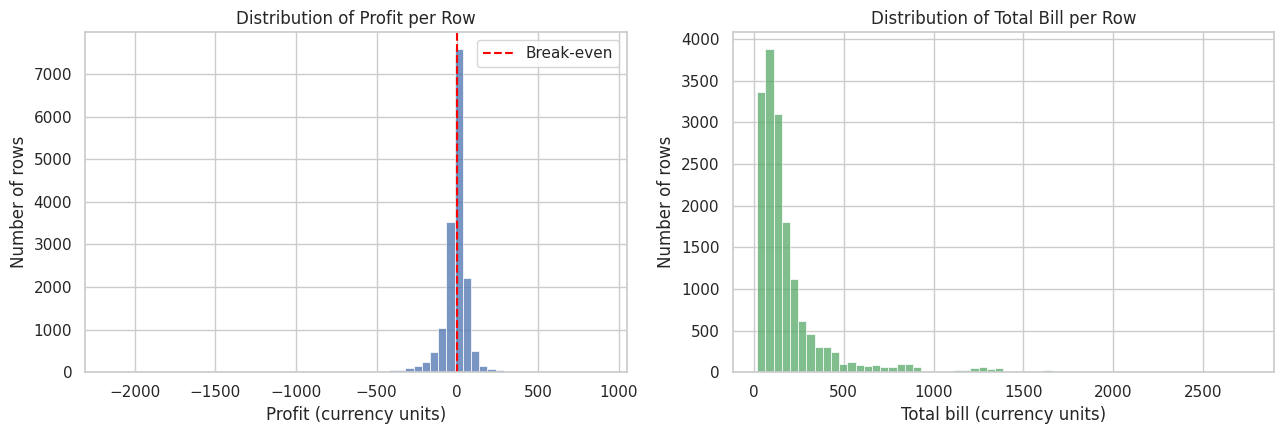

Median profit: -0.42 | Mean profit: -13.9


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(clean["Profit"], bins=60, color="#4C72B0", ax=ax[0])
ax[0].axvline(0, color="red", linestyle="--", label="Break-even")
ax[0].set_title("Distribution of Profit per Row")
ax[0].set_xlabel("Profit (currency units)"); ax[0].set_ylabel("Number of rows"); ax[0].legend()

sns.histplot(clean["Total_Bill"], bins=60, color="#55A868", ax=ax[1])
ax[1].set_title("Distribution of Total Bill per Row")
ax[1].set_xlabel("Total bill (currency units)"); ax[1].set_ylabel("Number of rows")
plt.tight_layout(); plt.savefig("figures/01_profit_bill_distribution.png", dpi=150, bbox_inches="tight"); plt.show()

print("Median profit:", clean["Profit"].median(), "| Mean profit:", round(clean["Profit"].mean(), 2))

**Interpretation:** most rows are small gains or small losses clustered around zero, but there is a long tail of **large losses**.
These few big losses pull the average below zero. Total bill is right-skewed, because a few expensive products (cakes) create very large bills.

### 12.2 Revenue vs profit by product

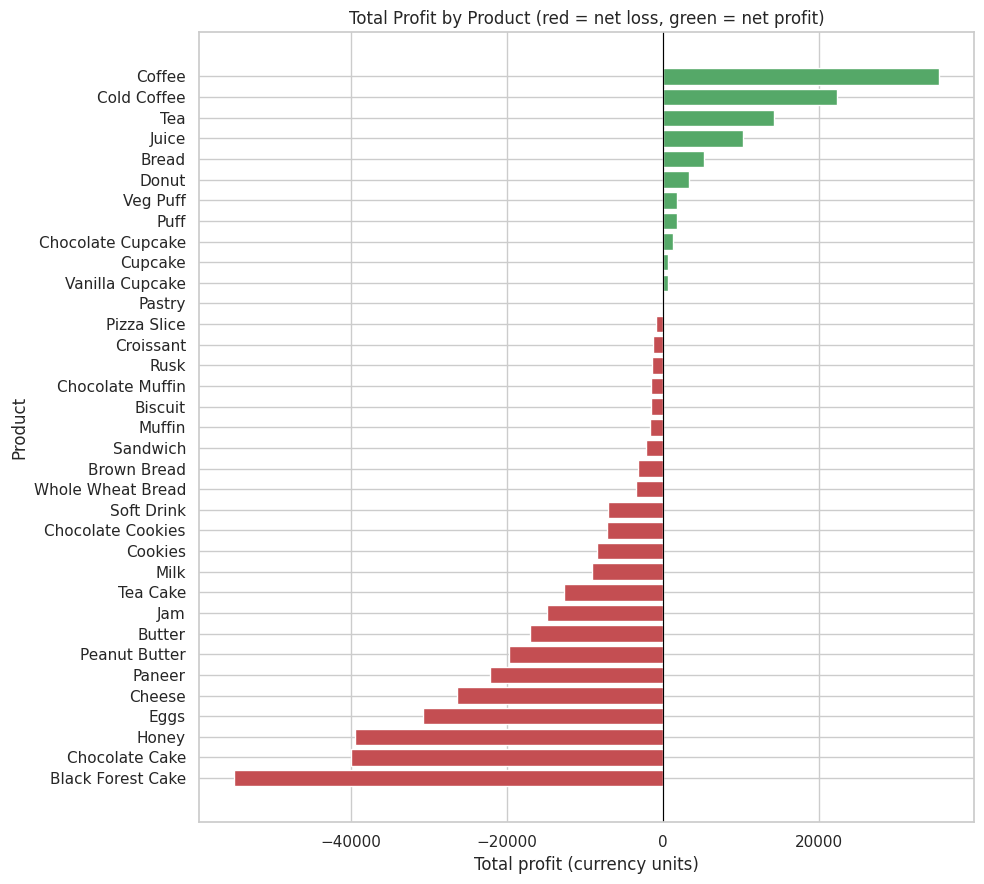

Products with a net loss: 23 of 35

Products with the largest losses


,Rows,Revenue,Profit,Waste_Cost,Loss_Rate
Product,,,,,
Black Forest Cake,495,529732.87,-54908.52,220480.04,58.2
Chocolate Cake,506,531066.35,-40012.97,206879.97,55.9
Honey,304,160684.62,-39437.53,88139.99,73.7
Eggs,568,85500.19,-30753.30,45359.98,87.3
Cheese,370,81651.24,-26385.09,44339.98,85.4
Paneer,387,76400.19,-22141.21,37399.99,76.5
Peanut Butter,363,159723.27,-19757.21,74499.97,63.1
Butter,585,77113.78,-17107.96,36540.04,69.2



Most profitable products


,Rows,Revenue,Profit,Waste_Cost,Loss_Rate
Product,,,,,
Coffee,868,104281.43,35301.44,20988.00,11.6
Cold Coffee,520,91001.41,22204.34,23212.00,22.7
Tea,560,39977.33,14168.81,8920.04,12.9
Juice,425,60250.57,10216.41,18550.02,31.8
Bread,1062,105149.05,5215.16,31020.05,37.9


In [12]:
prod = clean.groupby("Product").agg(Rows=("Profit", "size"), Revenue=("Revenue", "sum"), Profit=("Profit", "sum"),
                                    Waste_Cost=("Waste_Cost", "sum"), Loss_Rate=("Is_Loss", "mean")).sort_values("Profit")
prod["Loss_Rate"] = (prod["Loss_Rate"] * 100).round(1)

fig, ax = plt.subplots(figsize=(10, 9))
colors = ["#C44E52" if v < 0 else "#55A868" for v in prod["Profit"]]
ax.barh(prod.index, prod["Profit"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Total Profit by Product (red = net loss, green = net profit)")
ax.set_xlabel("Total profit (currency units)"); ax.set_ylabel("Product")
plt.tight_layout(); plt.savefig("figures/02_profit_by_product.png", dpi=150, bbox_inches="tight"); plt.show()

print("Products with a net loss:", (prod["Profit"] < 0).sum(), "of", len(prod))
print("\nProducts with the largest losses")
display(prod.head(8).round(2))
print("\nMost profitable products")
display(prod.tail(5).iloc[::-1].round(2))

**Interpretation:** most products lose money overall. The **cakes (Black Forest, Chocolate)**, **Honey** and **Eggs** lose the most.
Only a few products – mainly **coffee, cold coffee, tea and juice** – make a clear profit.

### 12.3 Category performance

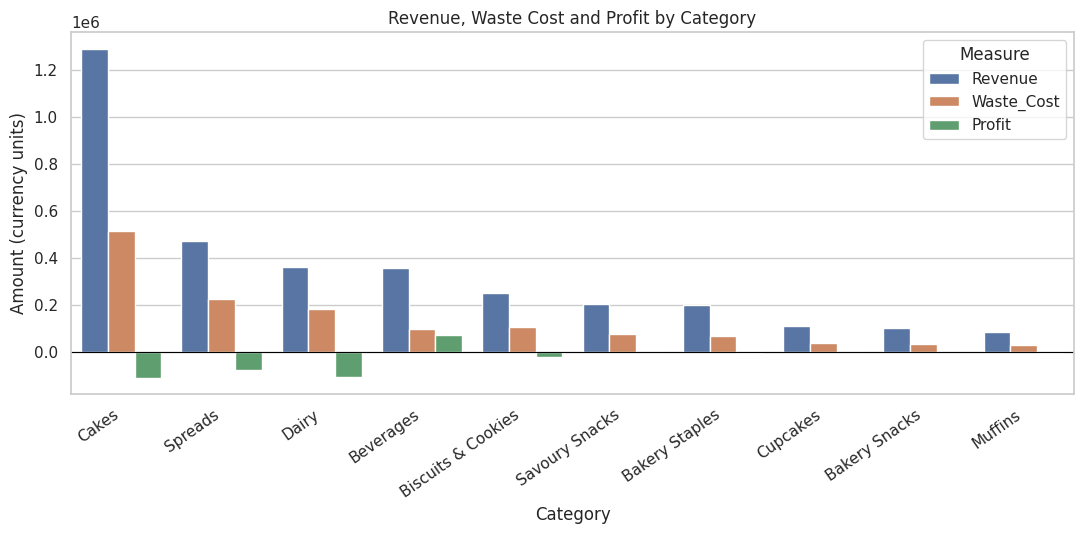

,Revenue,Waste_Cost,Profit
Category,,,
Cakes,1288747.25,515610.98,-107657.26
Spreads,471715.05,227979.99,-74018.07
Dairy,362120.30,181999.93,-105527.20
Beverages,356122.32,99195.05,74823.99
Biscuits & Cookies,253973.20,106720.02,-18558.17
Savoury Snacks,205352.82,75839.92,667.53
Bakery Staples,203043.67,70145.00,-1436.10
Cupcakes,112313.00,40845.98,2550.53
Bakery Snacks,105506.11,37559.95,1993.42


In [13]:
cat = clean.groupby("Category").agg(Revenue=("Revenue", "sum"), Waste_Cost=("Waste_Cost", "sum"), Profit=("Profit", "sum")).sort_values("Revenue", ascending=False)
cat_plot = cat.reset_index().melt(id_vars="Category", var_name="Measure", value_name="Amount")

fig, ax = plt.subplots(figsize=(11, 5.5))
sns.barplot(data=cat_plot, x="Category", y="Amount", hue="Measure", palette=["#4C72B0", "#DD8452", "#55A868"], ax=ax)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Revenue, Waste Cost and Profit by Category")
ax.set_xlabel("Category"); ax.set_ylabel("Amount (currency units)")
plt.xticks(rotation=35, ha="right"); plt.legend(title="Measure")
plt.tight_layout(); plt.savefig("figures/03_category_revenue_waste_profit.png", dpi=150, bbox_inches="tight"); plt.show()
display(cat.round(2))

**Interpretation:** **Cakes** bring the highest revenue yet the largest waste cost and the biggest loss, closely followed by **Dairy**. **Spreads** also lose heavily.
**Beverages** are the only large category with a strong profit.

### 12.4 Waste cost, shelf life and expiry risk

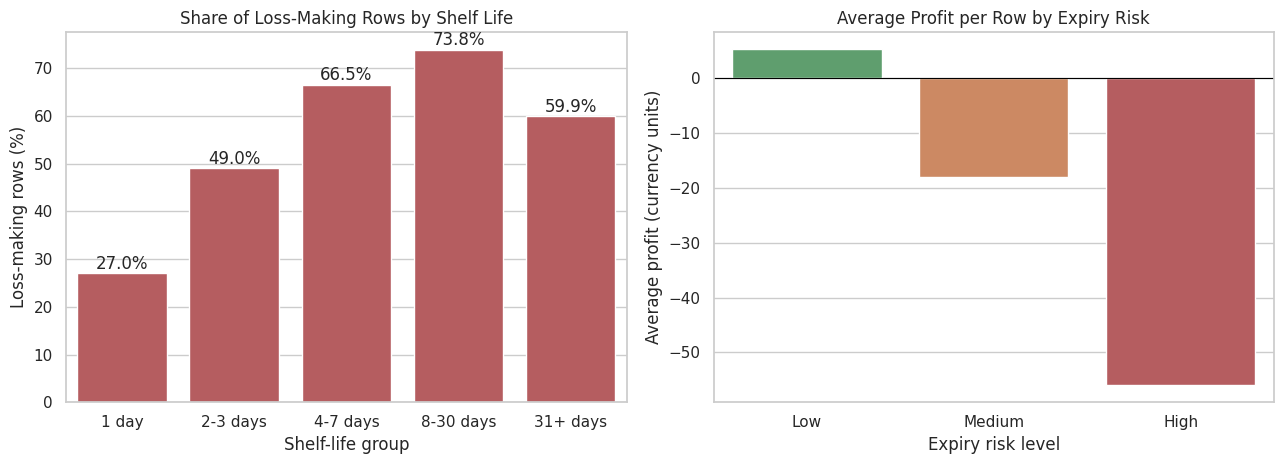

,Rows,Avg_Waste,Avg_Profit,Loss_Rate
Shelf_Life_Group,,,,
1 day,3339,39.15,23.63,27.0
2-3 days,7615,87.42,-13.19,49.0
4-7 days,849,122.44,-41.10,66.5
8-30 days,2150,96.23,-41.80,73.8
31+ days,2616,107.64,-32.12,59.9


In [14]:
shelf = clean.groupby("Shelf_Life_Group").agg(Rows=("Profit", "size"), Avg_Waste=("Waste_Cost", "mean"),
                                              Avg_Profit=("Profit", "mean"), Loss_Rate=("Is_Loss", "mean"))
shelf["Loss_Rate"] = (shelf["Loss_Rate"] * 100).round(1)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
sns.barplot(x=shelf.index.astype(str), y=shelf["Loss_Rate"], color="#C44E52", ax=ax[0])
ax[0].set_title("Share of Loss-Making Rows by Shelf Life")
ax[0].set_xlabel("Shelf-life group"); ax[0].set_ylabel("Loss-making rows (%)")
for i, v in enumerate(shelf["Loss_Rate"]): ax[0].text(i, v + 1, f"{v}%", ha="center")

risk = clean.groupby("Expiry_Risk")["Profit"].mean().reindex(["Low", "Medium", "High"])
sns.barplot(x=risk.index, y=risk.values, palette=["#55A868", "#DD8452", "#C44E52"], ax=ax[1])
ax[1].axhline(0, color="black", linewidth=0.8)
ax[1].set_title("Average Profit per Row by Expiry Risk")
ax[1].set_xlabel("Expiry risk level"); ax[1].set_ylabel("Average profit (currency units)")
plt.tight_layout(); plt.savefig("figures/04_shelf_life_expiry_risk.png", dpi=150, bbox_inches="tight"); plt.show()
display(shelf.round(2))

**Interpretation:** products with a **1-day shelf life** (such as coffee, tea and juice) are the *least* likely to lose money per row (27% of rows).
Loss rates are highest for items with a **4–30 day** shelf life (about 66–74% of rows). Rows labelled **High expiry risk**
lose far more on average than **Low risk** rows.

### 12.5 Discounts and promotions

,Rows,Avg_Discount_Pct,Avg_Quantity,Avg_Bill,Avg_Profit,Loss_Rate
Promotion_Applied,,,,,,
No,13209,3.21,2.60,215.77,0.15,41.7
Yes,3360,20.19,2.56,176.78,-69.13,84.6


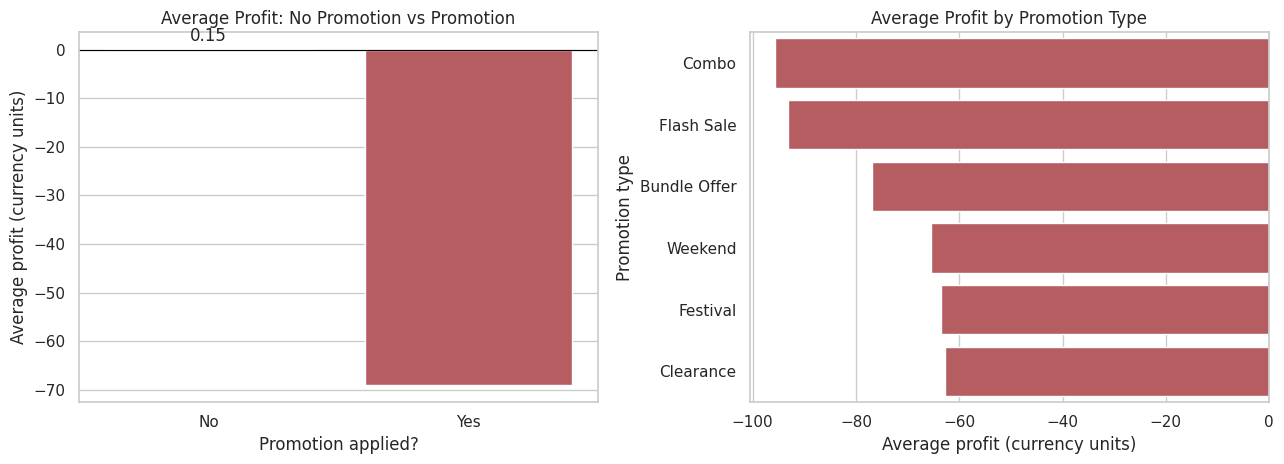

,Avg_Profit,Rows
Promotion_Type,,
Combo,-95.77,170
Flash Sale,-93.22,212
Bundle Offer,-76.84,209
Weekend,-65.53,2211
Festival,-63.54,362
Clearance,-62.78,196


In [15]:
promo = clean.groupby("Promotion_Applied").agg(Rows=("Profit", "size"), Avg_Discount_Pct=("Discount_Percentage", "mean"),
                                               Avg_Quantity=("Quantity", "mean"), Avg_Bill=("Total_Bill", "mean"),
                                               Avg_Profit=("Profit", "mean"), Loss_Rate=("Is_Loss", "mean"))
promo["Loss_Rate"] = (promo["Loss_Rate"] * 100).round(1)
display(promo.round(2))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
sns.barplot(data=clean, x="Promotion_Applied", y="Profit", estimator="mean", errorbar=None,
            palette=["#55A868", "#C44E52"], order=["No", "Yes"], ax=ax[0])
ax[0].axhline(0, color="black", linewidth=0.8)
ax[0].bar_label(ax[0].containers[0], fmt="%.2f", padding=3)   # show the exact value on each bar
ax[0].set_title("Average Profit: No Promotion vs Promotion")
ax[0].set_xlabel("Promotion applied?"); ax[0].set_ylabel("Average profit (currency units)")

ptype = clean[clean["Promo"] == 1].groupby("Promotion_Type").agg(Avg_Profit=("Profit", "mean"), Rows=("Profit", "size")).sort_values("Avg_Profit")
sns.barplot(x=ptype["Avg_Profit"], y=ptype.index, color="#C44E52", ax=ax[1])
ax[1].set_title("Average Profit by Promotion Type")
ax[1].set_xlabel("Average profit (currency units)"); ax[1].set_ylabel("Promotion type")
plt.tight_layout(); plt.savefig("figures/05_promotions.png", dpi=150, bbox_inches="tight"); plt.show()
display(ptype.round(2))

**Interpretation:** promotion rows average a **loss** while non-promotion rows are about break-even. Promotions are given at 10–30% discount, but
**average quantity bought does not increase** (about 2.6 items in both groups), so the discount does not seem to bring extra volume here. Every promotion type has a negative average profit.

### 12.6 Trends over time, store and season

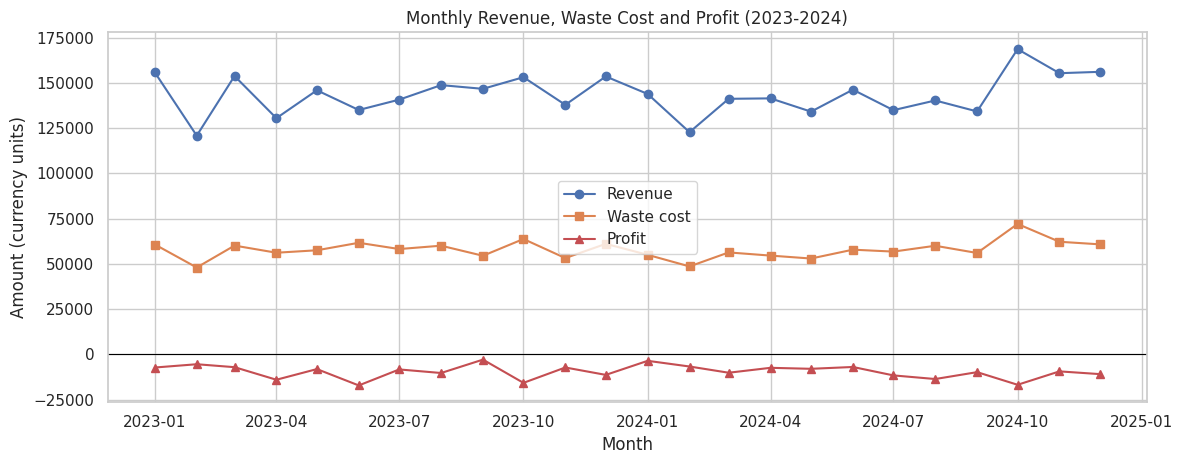

Months with negative profit: 24 of 24


In [16]:
monthly = clean.groupby(clean["Date"].dt.to_period("M")).agg(Revenue=("Revenue", "sum"), Profit=("Profit", "sum"), Waste=("Waste_Cost", "sum"))
monthly.index = monthly.index.to_timestamp()

fig, ax = plt.subplots(figsize=(12, 4.8))
ax.plot(monthly.index, monthly["Revenue"], marker="o", label="Revenue", color="#4C72B0")
ax.plot(monthly.index, monthly["Waste"], marker="s", label="Waste cost", color="#DD8452")
ax.plot(monthly.index, monthly["Profit"], marker="^", label="Profit", color="#C44E52")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Monthly Revenue, Waste Cost and Profit (2023-2024)")
ax.set_xlabel("Month"); ax.set_ylabel("Amount (currency units)"); ax.legend()
plt.tight_layout(); plt.savefig("figures/06_monthly_trend.png", dpi=150, bbox_inches="tight"); plt.show()
print("Months with negative profit:", (monthly["Profit"] < 0).sum(), "of", len(monthly))

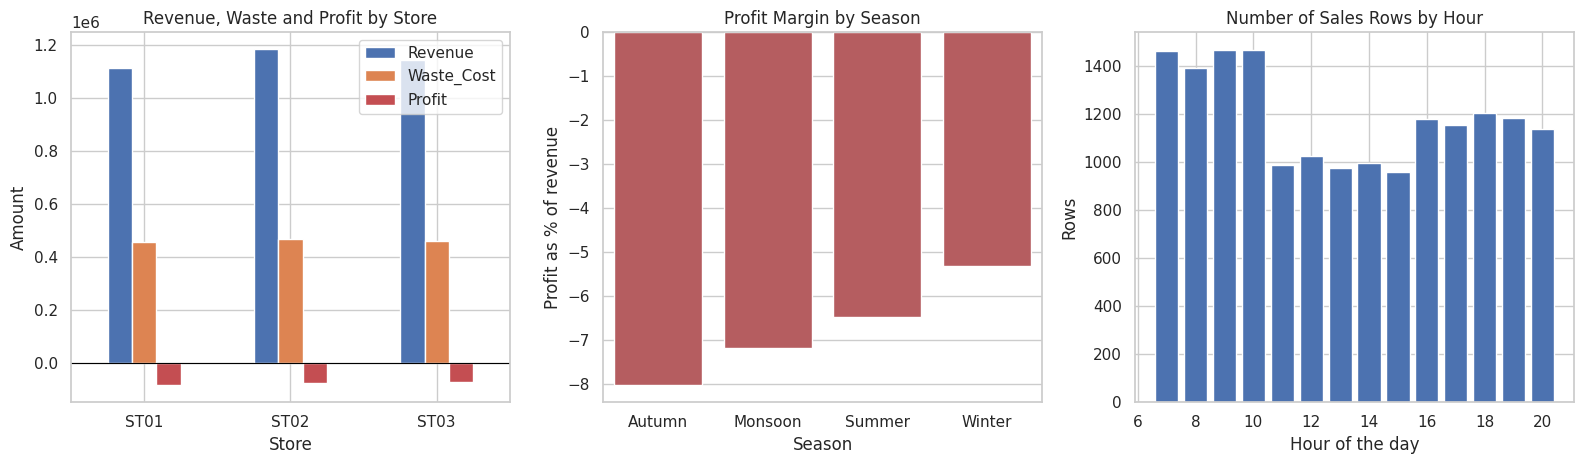

,Revenue,Waste_Cost,Profit
Store_ID,,,
ST01,1115030.02,456860.35,-83213.28
ST02,1184448.13,469916.00,-75319.83
ST03,1144634.80,462036.45,-71806.14


,Revenue,Profit,Profit_per_Revenue_%
Season,,,
Autumn,615432.93,-49264.62,-8.00
Monsoon,1127683.53,-80866.11,-7.17
Summer,847525.39,-54878.83,-6.48
Winter,853471.10,-45329.69,-5.31


In [17]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))

store = clean.groupby("Store_ID")[["Revenue", "Waste_Cost", "Profit"]].sum()
store.plot(kind="bar", ax=ax[0], color=["#4C72B0", "#DD8452", "#C44E52"], rot=0)
ax[0].axhline(0, color="black", linewidth=0.8)
ax[0].set_title("Revenue, Waste and Profit by Store"); ax[0].set_xlabel("Store"); ax[0].set_ylabel("Amount")

season = clean.groupby("Season").agg(Revenue=("Revenue", "sum"), Profit=("Profit", "sum"))
season["Profit_per_Revenue_%"] = season["Profit"] / season["Revenue"] * 100
sns.barplot(x=season.index, y=season["Profit_per_Revenue_%"], color="#C44E52", ax=ax[1])
ax[1].set_title("Profit Margin by Season"); ax[1].set_xlabel("Season"); ax[1].set_ylabel("Profit as % of revenue")

hour = clean.groupby("Hour").size()
ax[2].bar(hour.index, hour.values, color="#4C72B0")
ax[2].set_title("Number of Sales Rows by Hour"); ax[2].set_xlabel("Hour of the day"); ax[2].set_ylabel("Rows")
plt.tight_layout(); plt.savefig("figures/07_store_season_hour.png", dpi=150, bbox_inches="tight"); plt.show()
display(store.round(2)); display(season.round(2))

**Interpretation:** the loss is **spread evenly** over every month, every store and every season, so it is not a one-off problem
in one location or one period. This points to **product and pricing/production decisions**, not to a specific store or time of year.
Sales are highest in the morning (7–10) and early evening (16–20).

### 12.7 Customers

,Avg_Bill,Avg_Disc
Loyalty_Member,,
No,208.96,6.67
Yes,205.93,6.62


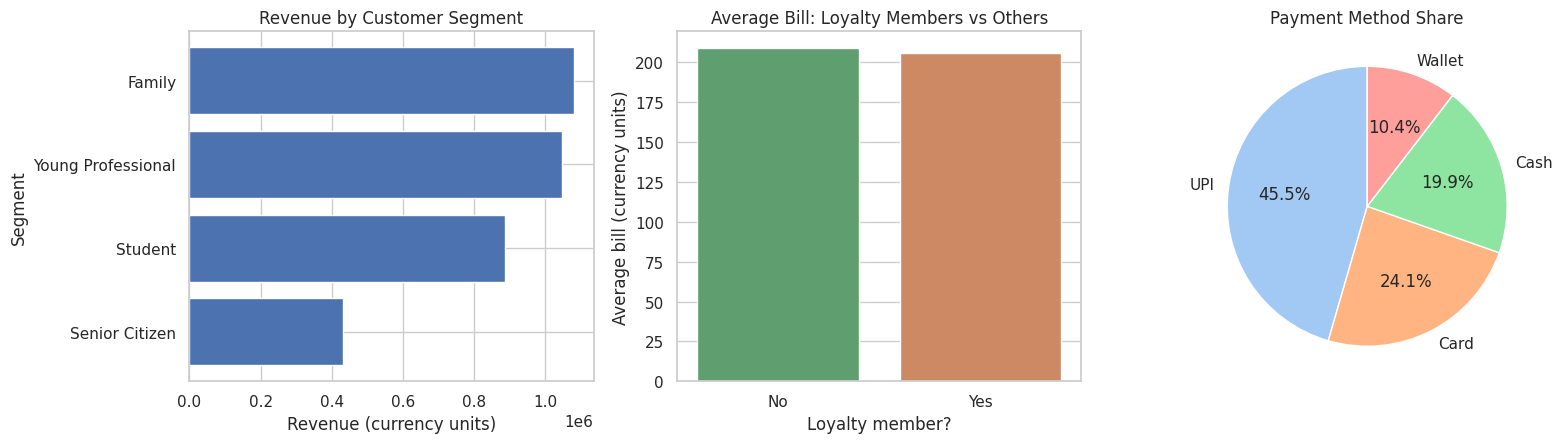

Average rating: 3.68


,count,mean
Customer_Rating,,
1,56,1.55
2,1112,-9.81
3,5498,-14.94
4,7362,-14.04
5,2541,-13.37


In [18]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
seg = clean.groupby("Customer_Segment")["Revenue"].sum().sort_values()
ax[0].barh(seg.index, seg.values, color="#4C72B0"); ax[0].set_title("Revenue by Customer Segment")
ax[0].set_xlabel("Revenue (currency units)"); ax[0].set_ylabel("Segment")

loy = clean.groupby("Loyalty_Member").agg(Avg_Bill=("Total_Bill", "mean"), Avg_Disc=("Discount_Percentage", "mean"))
sns.barplot(x=loy.index, y=loy["Avg_Bill"], palette=["#55A868", "#DD8452"], order=["No", "Yes"], ax=ax[1])
ax[1].set_title("Average Bill: Loyalty Members vs Others"); ax[1].set_xlabel("Loyalty member?"); ax[1].set_ylabel("Average bill (currency units)")
display(loy.round(2))

pay = clean["Payment_Method"].value_counts()
ax[2].pie(pay.values, labels=pay.index, autopct="%1.1f%%", startangle=90, colors=sns.color_palette("pastel"))
ax[2].set_title("Payment Method Share")
plt.tight_layout(); plt.savefig("figures/08_customers.png", dpi=150, bbox_inches="tight"); plt.show()

print("Average rating:", round(clean["Customer_Rating"].mean(), 2))
display(clean.groupby("Customer_Rating")["Profit"].agg(["count", "mean"]).round(2))

**Interpretation:** Young professionals, families and students bring most revenue. Loyalty members spend and get discounts about the same as
non-members, so the loyalty programme does not currently create a visibly different customer. Customer rating is almost unrelated to profit.

### 12.8 Correlation analysis

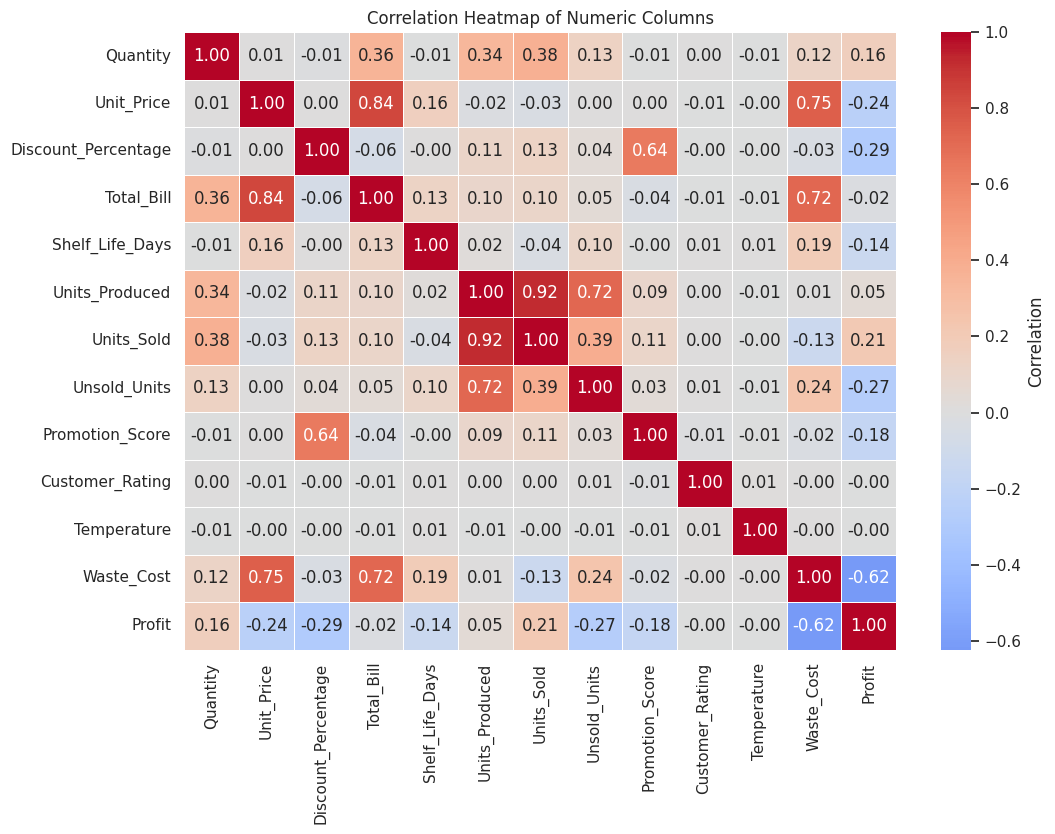

Correlation of each variable with Profit:


,correlation_with_profit
Waste_Cost,-0.62
Discount_Percentage,-0.29
Unsold_Units,-0.27
Unit_Price,-0.24
Promotion_Score,-0.18
Shelf_Life_Days,-0.14
Total_Bill,-0.02
Temperature,-0.00
Customer_Rating,-0.00
Units_Produced,0.05


In [19]:
num_cols = ["Quantity", "Unit_Price", "Discount_Percentage", "Total_Bill", "Shelf_Life_Days", "Units_Produced",
            "Units_Sold", "Unsold_Units", "Promotion_Score", "Customer_Rating", "Temperature", "Waste_Cost", "Profit"]
corr = clean[num_cols].corr()

plt.figure(figsize=(11, 8.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.4, cbar_kws={"label": "Correlation"})
plt.title("Correlation Heatmap of Numeric Columns")
plt.tight_layout(); plt.savefig("figures/09_correlation_heatmap.png", dpi=150, bbox_inches="tight"); plt.show()

print("Correlation of each variable with Profit:")
display(corr["Profit"].drop("Profit").sort_values().round(2).to_frame("correlation_with_profit"))

**Interpretation:** `Profit` has its strongest **negative** link with `Waste_Cost` (about -0.62), followed by weaker negative links with
`Discount_Percentage` (-0.29), `Unsold_Units` (-0.27) and `Unit_Price` (-0.24). `Quantity` has a small positive link (+0.16).
Temperature and customer rating are almost unrelated to profit.
*Correlation shows association, not cause.*

## 13. Statistical Testing
We test two simple business questions. A p-value below 0.05 is treated as a statistically significant difference.

**Test 1 – Does a promotion change profit?** (Mann-Whitney U test, because profit is not normally distributed.)  
**Test 2 – Is the promotion/loss link real?** (Chi-square test of independence between `Promotion_Applied` and `Is_Loss`.)  
**Test 3 – Do promotions change the quantity bought?** (Mann-Whitney U test.)

In [20]:
def fmt_p(p):
    return "< 0.001" if p < 0.001 else f"{p:.3f}"

promo_profit = clean.loc[clean["Promo"] == 1, "Profit"]
nopromo_profit = clean.loc[clean["Promo"] == 0, "Profit"]
u, p1 = stats.mannwhitneyu(promo_profit, nopromo_profit, alternative="two-sided")
print(f"Test 1  Mann-Whitney (profit, promo vs no promo): p-value {fmt_p(p1)}")

chi2, p2, dof, _ = stats.chi2_contingency(pd.crosstab(clean["Promotion_Applied"], clean["Is_Loss"]))
print(f"Test 2  Chi-square (promotion vs loss):          p-value {fmt_p(p2)}")

u3, p3 = stats.mannwhitneyu(clean.loc[clean["Promo"] == 1, "Quantity"], clean.loc[clean["Promo"] == 0, "Quantity"], alternative="two-sided")
print(f"Test 3  Mann-Whitney (quantity, promo vs no promo): p-value {fmt_p(p3)}")
print("Mean quantity  promo: {:.3f}  | no promo: {:.3f}".format(clean.loc[clean['Promo']==1,'Quantity'].mean(), clean.loc[clean['Promo']==0,'Quantity'].mean()))

Test 1  Mann-Whitney (profit, promo vs no promo): p-value < 0.001
Test 2  Chi-square (promotion vs loss):          p-value < 0.001
Test 3  Mann-Whitney (quantity, promo vs no promo): p-value 0.103
Mean quantity  promo: 2.563  | no promo: 2.598


**Interpretation:** Tests 1 and 2 give p-values below 0.001, so the lower profit and higher loss rate on promotion rows is **statistically
significant**. Test 3 gives p = 0.103 (above 0.05), so we **cannot say** that promotions change the quantity bought: average quantity is 2.56 with promotion and 2.60 without.
We avoid claiming that promotions *cause* the loss, because the dataset is observational.

## 14. Machine Learning: Predicting Loss-Making Transactions

### 14.1 Why this model and what is the target?
* **Goal:** predict `Is_Loss` (1 = loss-making row, 0 = profitable or break-even row). This is a **binary classification** problem.
* **Why it is useful:** a bakery manager could check, before setting a price or planning production, which
  product/discount combinations are likely to lose money.
* **Models:** Logistic Regression (simple and explainable) and Random Forest (captures non-linear patterns), compared with a
  "predict the majority class" baseline.

### 14.2 Avoiding target leakage
`Profit` is calculated from revenue, cost and waste. If we give the model `Waste_Cost`, `Profit`, `Profit_Margin_%`, `Unsold_Units`,
`Stock_Available`, `Units_Sold`, `Sell_Through_%` or `Expiry_Risk`, it would be using information that is only known *after* the day ends, or that is
calculated from the answer. So these are **excluded**. We also exclude IDs, dates, customer rating (given after purchase) and the
recommendation columns.

**Features used (known at sale / production-planning time):** product, category, unit price, quantity, discount %, promotion applied and type,
shelf-life days, units produced (the planned batch size), season, weekend, hour, store, payment method, loyalty, customer segment and age.

### 14.3 Correct evaluation: split by time
Random splitting would mix 2023 and 2024 rows from the same product-day batch into both train and test sets, which makes scores look better than reality.
Instead we **train on 2023 and test on 2024**, as a real bakery would use last year's data to predict the next.

In [21]:
feature_cols_cat = ["Product", "Category", "Promotion_Applied", "Promotion_Type", "Season", "Weekend", "Store_ID",
                    "Payment_Method", "Loyalty_Member", "Customer_Segment"]
feature_cols_num = ["Unit_Price", "Quantity", "Discount_Percentage", "Shelf_Life_Days", "Units_Produced", "Hour", "Customer_Age"]
target = "Is_Loss"

leaky = ["Profit", "Profit_Margin_%", "Waste_Cost", "Unsold_Units", "Stock_Available", "Units_Sold", "Sell_Through_%", "Expiry_Risk"]
assert not set(leaky) & set(feature_cols_cat + feature_cols_num), "A leaky column is in the features!"

train = clean[clean["Year"] == 2023]
test = clean[clean["Year"] == 2024]
X_train, y_train = train[feature_cols_cat + feature_cols_num], train[target]
X_test, y_test = test[feature_cols_cat + feature_cols_num], test[target]

print("Train rows (2023):", len(X_train), "| Test rows (2024):", len(X_test))
print("Loss share  train: {:.1%} | test: {:.1%}".format(y_train.mean(), y_test.mean()))

Train rows (2023): 8190 | Test rows (2024): 8379
Loss share  train: 49.9% | test: 50.9%


### 14.4 Build, tune and train the models

In [22]:
preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), feature_cols_cat),
    ("num", StandardScaler(), feature_cols_num),
])

baseline = Pipeline([("prep", preprocess), ("model", DummyClassifier(strategy="most_frequent"))])
logreg = Pipeline([("prep", preprocess), ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))])
forest = Pipeline([("prep", preprocess), ("model", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))])

# A small grid search. Cross-validation happens only inside the 2023 training data.
# The cv folds are ordered by position, so we sort by date first to respect time.
train_sorted = train.sort_values("Date")
Xs, ys = train_sorted[feature_cols_cat + feature_cols_num], train_sorted[target]

from sklearn.model_selection import TimeSeriesSplit
tscv = TimeSeriesSplit(n_splits=4)

grid_forest = GridSearchCV(forest, {"model__n_estimators": [150, 300],
                                    "model__max_depth": [8, 14, None],
                                    "model__min_samples_leaf": [3, 10]},
                           cv=tscv, scoring="roc_auc", n_jobs=-1)
grid_forest.fit(Xs, ys)
print("Best Random Forest settings:", grid_forest.best_params_)
print("Best cross-validated ROC-AUC (inside 2023):", round(grid_forest.best_score_, 4))

grid_lr = GridSearchCV(logreg, {"model__C": [0.1, 1, 10]}, cv=tscv, scoring="roc_auc", n_jobs=-1)
grid_lr.fit(Xs, ys)
print("Best Logistic Regression C:", grid_lr.best_params_, "| CV ROC-AUC:", round(grid_lr.best_score_, 4))

baseline.fit(X_train, y_train)
best_lr = grid_lr.best_estimator_
best_rf = grid_forest.best_estimator_

Best Random Forest settings: {'model__max_depth': None, 'model__min_samples_leaf': 3, 'model__n_estimators': 150}
Best cross-validated ROC-AUC (inside 2023): 0.8688
Best Logistic Regression C: {'model__C': 0.1} | CV ROC-AUC: 0.8425


### 14.5 Evaluate on the unseen 2024 data

In [23]:
def evaluate(name, model):
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    return {"Model": name,
            "Accuracy": accuracy_score(y_test, pred),
            "Precision": precision_score(y_test, pred, zero_division=0),
            "Recall": recall_score(y_test, pred, zero_division=0),
            "F1": f1_score(y_test, pred, zero_division=0),
            "ROC-AUC": roc_auc_score(y_test, proba)}

results = pd.DataFrame([evaluate("Baseline (majority class)", baseline),
                        evaluate("Logistic Regression", best_lr),
                        evaluate("Random Forest", best_rf)]).set_index("Model").round(3)
display(results)

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Baseline (majority class),0.491,0.000,0.000,0.000,0.500
Logistic Regression,0.748,0.759,0.740,0.749,0.833
Random Forest,0.790,0.804,0.777,0.791,0.871


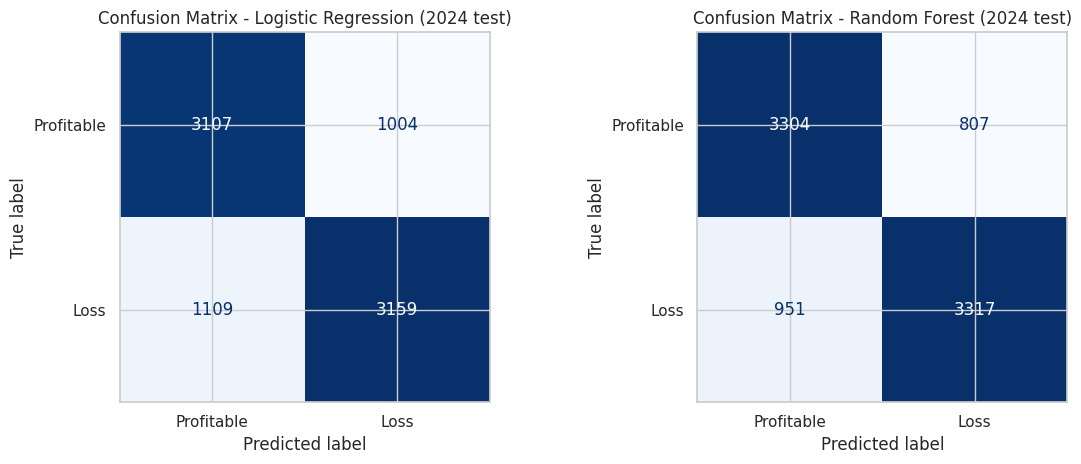

Random Forest classification report (2024 test data)
              precision    recall  f1-score   support

  Profitable       0.78      0.80      0.79      4111
        Loss       0.80      0.78      0.79      4268

    accuracy                           0.79      8379
   macro avg       0.79      0.79      0.79      8379
weighted avg       0.79      0.79      0.79      8379



In [24]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
for a, (name, m) in zip(ax, [("Logistic Regression", best_lr), ("Random Forest", best_rf)]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, m.predict(X_test)),
                           display_labels=["Profitable", "Loss"]).plot(ax=a, cmap="Blues", colorbar=False)
    a.set_title(f"Confusion Matrix - {name} (2024 test)")
plt.tight_layout(); plt.savefig("figures/10_confusion_matrices.png", dpi=150, bbox_inches="tight"); plt.show()

print("Random Forest classification report (2024 test data)")
print(classification_report(y_test, best_rf.predict(X_test), target_names=["Profitable", "Loss"]))

### 14.6 What does the model rely on?

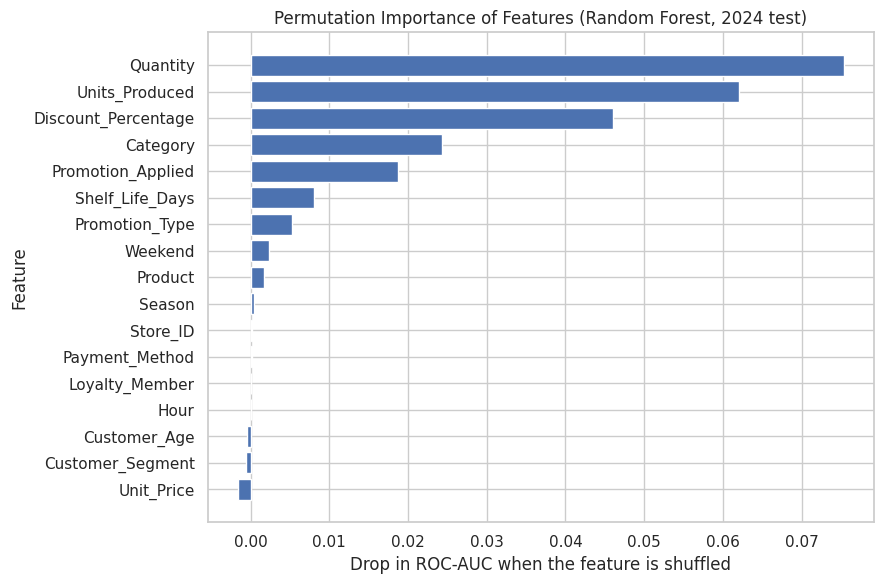

,importance
Quantity,0.0754
Units_Produced,0.0620
Discount_Percentage,0.0461
Category,0.0243
Promotion_Applied,0.0187
Shelf_Life_Days,0.0081
Promotion_Type,0.0053
Weekend,0.0023
Product,0.0016
Season,0.0004


In [25]:
from sklearn.inspection import permutation_importance

# Permutation importance on the test set: how much does the score drop when one column is shuffled?
perm = permutation_importance(best_rf, X_test, y_test, scoring="roc_auc", n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()

plt.figure(figsize=(9, 6))
plt.barh(imp.index, imp.values, color="#4C72B0")
plt.title("Permutation Importance of Features (Random Forest, 2024 test)")
plt.xlabel("Drop in ROC-AUC when the feature is shuffled"); plt.ylabel("Feature")
plt.tight_layout(); plt.savefig("figures/11_feature_importance.png", dpi=150, bbox_inches="tight"); plt.show()
display(imp.sort_values(ascending=False).round(4).to_frame("importance"))

The chart ranks `Quantity`, `Units_Produced` and `Discount_Percentage` highest. To see *why*, we look at the raw loss rates behind the top features.

In [26]:
q = clean.groupby("Quantity")["Is_Loss"].agg(["mean", "size"])
q["mean"] = (q["mean"] * 100).round(1)
q.columns = ["Loss_Rate_%", "Rows"]
print("Loss rate by quantity bought")
display(q)

clean["Units_Produced_Band"] = pd.cut(clean["Units_Produced"], bins=[0, 4, 7, 10, 40], labels=["2-4", "5-7", "8-10", "11+"])
b = clean.groupby("Units_Produced_Band", observed=True)["Is_Loss"].agg(["mean", "size"])
b["mean"] = (b["mean"] * 100).round(1)
b.columns = ["Loss_Rate_%", "Rows"]
print("Loss rate by units produced (batch size)")
display(b)

d = clean.assign(Discount_Band=pd.cut(clean["Discount_Percentage"], bins=[-0.1, 0, 5, 10, 20, 30],
                                       labels=["0%", "0-5%", "5-10%", "10-20%", "20-30%"]))
dd = d.groupby("Discount_Band", observed=True)["Is_Loss"].agg(["mean", "size"])
dd["mean"] = (dd["mean"] * 100).round(1)
dd.columns = ["Loss_Rate_%", "Rows"]
print("Loss rate by discount band")
display(dd)

Loss rate by quantity bought


,Loss_Rate_%,Rows
Quantity,,
1,70.1,3401
2,54.7,5349
3,42.4,4243
4,36.2,2198
5,33.4,964
6,30.4,414


Loss rate by units produced (batch size)


,Loss_Rate_%,Rows
Units_Produced_Band,,
2-4,64.7,3986
5-7,51.7,5978
8-10,39.8,3230
11+,41.5,3375


Loss rate by discount band


,Loss_Rate_%,Rows
Discount_Band,,
0%,39.4,5344
0-5%,37.0,3836
5-10%,47.9,3142
10-20%,67.4,2542
20-30%,94.3,1705


### 14.7 Interpretation of the model results
* **Baseline:** always predicting the most common class gives 0.491 accuracy and ROC-AUC 0.500 (no skill). Both models beat it clearly.
* **Models:** on the unseen 2024 data, Random Forest scores accuracy 0.790, F1 0.791 and ROC-AUC 0.871, compared with 0.748, 0.749 and 0.833 for Logistic Regression.
  The Random Forest is therefore the better model here. It finds about 78% of loss-making rows (recall) and about 80% of its "loss" warnings are correct (precision).
* **Important features:** the permutation-importance chart ranks `Quantity`, `Units_Produced`, `Discount_Percentage`, `Category` and `Promotion_Applied` highest.
  `Product` and `Unit_Price` score near zero, but this does **not** mean they are unimportant: they overlap with `Category`, so shuffling one of them
  barely hurts the model because the others still carry the same information.
* **What the raw tables show:** loss rate drops as quantity per row rises (70% at 1 unit, 30% at 6 units), rises sharply with deeper discounts
  (39% at 0% discount, 94% at 20-30%), and is higher for small batches (65% for 2-4 units produced, 40% for 8-10). The batch-size result is probably mixed up with
  the product mix (expensive cakes are made in small batches), so it should not be read as "bigger batches are better".

**Cautions:** the dataset is synthetic, the 2023/2024 profit rules appear very similar, and rows from the same product-day share batch values. The model score is therefore
an estimate of how well patterns in *this* dataset repeat, not a guarantee for a real bakery.

## 15. Key Findings

In [27]:
promo_row = promo.loc["Yes"]; nopromo_row = promo.loc["No"]
worst = prod.head(3).index.tolist(); best = prod.tail(3).index.tolist()[::-1]
cake_cat = cat.loc["Cakes"]

findings = [
    f"Total profit is {total_profit:,.0f} on revenue of {total_rev:,.0f}; recorded waste cost equals {total_waste/total_rev*100:.1f}% of revenue.",
    f"{(prod['Profit'] < 0).sum()} of {len(prod)} products have a net loss. Largest losses: {', '.join(worst)}.",
    f"Most profitable products: {', '.join(best)}.",
    f"Cakes bring {cake_cat['Revenue']:,.0f} revenue but {cake_cat['Waste_Cost']:,.0f} waste cost and {cake_cat['Profit']:,.0f} profit.",
    f"Promotion rows lose {promo_row['Avg_Profit']:.2f} per row on average vs {nopromo_row['Avg_Profit']:.2f} without promotion; "
    f"loss rate {promo_row['Loss_Rate']}% vs {nopromo_row['Loss_Rate']}%.",
    f"Average quantity bought: {promo_row['Avg_Quantity']:.2f} with promotion vs {nopromo_row['Avg_Quantity']:.2f} without.",
    f"Loss is spread across all stores, seasons and {(monthly['Profit'] < 0).sum()} of {len(monthly)} months.",
    f"Best model on 2024 data: Random Forest with ROC-AUC {results.loc['Random Forest','ROC-AUC']}, "
    f"recall {results.loc['Random Forest','Recall']} (baseline ROC-AUC {results.loc['Baseline (majority class)','ROC-AUC']}).",
]
for i, f in enumerate(findings, 1):
    print(f"{i}. {f}")

1. Total profit is -230,339 on revenue of 3,444,113; recorded waste cost equals 40.3% of revenue.
2. 23 of 35 products have a net loss. Largest losses: Black Forest Cake, Chocolate Cake, Honey.
3. Most profitable products: Coffee, Cold Coffee, Tea.
4. Cakes bring 1,288,747 revenue but 515,611 waste cost and -107,657 profit.
5. Promotion rows lose -69.13 per row on average vs 0.15 without promotion; loss rate 84.6% vs 41.7%.
6. Average quantity bought: 2.56 with promotion vs 2.60 without.
7. Loss is spread across all stores, seasons and 24 of 24 months.
8. Best model on 2024 data: Random Forest with ROC-AUC 0.871, recall 0.777 (baseline ROC-AUC 0.5).


## 16. Recommendations
These are suggestions that follow from the analysis above. They should be tested before large-scale use.

1. **Review production planning for high-waste products** (cakes, dairy, spreads, eggs, honey): these items create the largest waste costs. Match production more closely to demand, for example by making cakes to order. The data cannot tell us the best batch size, because batch size is mixed up with product type, so this should be tested.
2. **Review discounting rules.** Rows with a 20-30% discount are loss-making 94% of the time, and promotions did not show a significant change in quantity bought. Pause or redesign the deepest discounts and test the change on a few products.
3. **Review pricing of loss-making products.** Where the selling price is below the cost plus expected waste, raise the price or drop the item.
4. **Protect and promote the profitable products** (coffee, cold coffee, tea, juice, bread). Use them to attract customers and bundle them carefully with high-margin items.
5. **Use the loss-prediction model as a screening tool** (for example, before a promotion is launched), and retrain it with new data. Treat it as decision support, not as a replacement for judgement.
6. **Improve data capture:** record waste per batch (not per sale row) and state the currency, cost price and the rule behind `Profit` so that future analysis is more reliable.

## 17. Limitations
* The dataset is **synthetic**; real bakery behaviour may differ.
* Production, sales and waste values are identical for rows from the same date, store and product, while `Waste_Cost` and `Profit` are listed per row. If waste were charged on every row of a batch, losses could be overstated. The data does not explain how `Profit` is calculated, so we used it as provided.
* No cost-price column is provided, and currency is unspecified.
* The two years look very alike, so a train-on-2023 / test-on-2024 score may be optimistic compared with a real change in business conditions.
* Findings show association, not proof of cause.

## 18. Conclusion
The analysis shows that the bakery's problem lies in **what is produced, how much is wasted, and how it is discounted**, not in a particular store or season. A small number of
products (cakes, honey, eggs, dairy, spreads) drive most of the loss, while beverages and a few quick-selling items make profit. Promotions line up with weaker profit
and did not raise quantity per purchase in this dataset. A Random Forest model, trained on 2023 and evaluated on 2024 without leakage, flags loss-making rows with ROC-AUC 0.871 and recall 0.777 (Section 14.5).
Deep discounts, low quantity per row and the product/category mix stand out in the data. Reviewing discount rules, production planning for high-waste products and pricing is the most promising next step.

*End of notebook.*